# TP 3 — Prompting : la même tâche avec un LLM

On reprend **exactement la même tâche et le même test** que le TP 2 (qui parle ? 7 personnages) mais sans entraîner de modèle : la tâche est décrite **dans le contexte** (instructions, exemples), et un LLM pré-entraîné produit la réponse.

| Étape | Contenu |
|---|---|
| 1 | Prompting : rôles system/user, zero-shot, zero-shot + contexte, few-shot, sortie JSON |
| 2 | Modèle LLM : modèle à poids ouverts via 🤗 `transformers` (ou API, au choix) |
| 3 | Sortie générée : décodage, parsing JSON, sorties invalides, effet de la température |
| 4 | Évaluation : mêmes métriques qu'au TP 2, + coût/latence, comparaison classique vs LLM |

> ⚙️ **Exécuter sur Colab avec un GPU T4** (Exécution → Modifier le type d'exécution). Compter ~10-15 min avec `Qwen2.5-1.5B-Instruct`.

In [11]:
!pip -q install -U transformers accelerate

In [12]:
import json, time, warnings
import matplotlib.pyplot as plt
import seaborn as sns
import torch
warnings.filterwarnings("ignore")
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 0. Données : même pipeline et même split que le TP 2

In [13]:
import os, re, random
import numpy as np
import pandas as pd
from urllib.request import urlretrieve
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED)

if not os.path.exists("input.txt"):
    urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/"
                "data/tinyshakespeare/input.txt", "input.txt")
with open("input.txt", encoding="utf-8") as f:
    raw = f.read()

# 1 réplique = un bloc séparé par une ligne vide : "NOM:\ntexte..."
records = []
for block in raw.strip().split("\n\n"):
    lines = block.split("\n")
    if len(lines) > 1 and re.fullmatch(r"[A-Z][A-Za-z' .-]*:", lines[0]):
        records.append({"speaker": lines[0][:-1], "text": " ".join(l.strip() for l in lines[1:])})
df_all = pd.DataFrame(records)

# 7 personnages, chacun d'une pièce différente
PLAYS = {
    "GLOUCESTER": "Richard III / Henry VI (Richard, duc de Gloucester)",
    "DUKE VINCENTIO": "Measure for Measure",
    "MENENIUS": "Coriolanus",
    "ROMEO": "Romeo and Juliet",
    "PETRUCHIO": "The Taming of the Shrew",
    "LEONTES": "The Winter's Tale",
    "KING RICHARD II": "Richard II",
}
LABELS = list(PLAYS)
df = df_all[df_all.speaker.isin(LABELS)].copy()
df["text"] = df.text.str.replace(r"\s+", " ", regex=True).str.strip()
df = df[df.text.str.split().str.len() >= 3]                 # répliques trop courtes : pas de signal
df = df.drop_duplicates("text").reset_index(drop=True)       # dédupliquer AVANT le split
df["label"] = df.speaker.map({s: i for i, s in enumerate(LABELS)})

# split stratifié 70 / 15 / 15
train_df, tmp = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp.label, random_state=SEED)
print(f"{len(df_all)} répliques au total -> {len(df)} retenues | train {len(train_df)} / val {len(val_df)} / test {len(test_df)}")

7093 répliques au total -> 1066 retenues | train 746 / val 160 / test 160


In [14]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix)

def scores(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "precision_macro": p, "recall_macro": r, "f1_macro": f}

In [15]:
# Sous-échantillon du test (stratifié) pour limiter le temps de génération.
# N_TEST = None -> tout le test (≈ 160 répliques).
N_TEST = None
eval_df = test_df if N_TEST is None else test_df.groupby("label").sample(n=N_TEST // len(LABELS), random_state=SEED)
y_eval = eval_df.label.values
print(len(eval_df), "répliques évaluées")

160 répliques évaluées


## 1. Prompting

Un prompt = une **spécification testable** (objectif, contexte, contraintes, format, exemples, critères). On compare 4 variantes, de la plus simple à la plus riche :

| Variante | Contenu |
|---|---|
| **P1 zero-shot** | instruction + liste des 7 noms |
| **P2 zero-shot + contexte** | + la pièce de chaque personnage (connaissance que le LLM peut mobiliser) |
| **P3 few-shot** | P2 + 1 exemple court par personnage, tiré du **train** |
| **P4 few-shot + raisonnement court** | P3 + un champ `indice` à remplir avant la réponse |

Bonnes pratiques appliquées :
- **rôles séparés** : règles stables dans `system`, la réplique dans `user` ;
- la réplique est **délimitée** (`<replique>…</replique>`) et traitée comme une donnée, jamais comme une instruction ;
- **sortie JSON** avec un label contraint à une liste fermée → parsing automatique et mesurable ;
- exemples few-shot choisis **dans le train uniquement** (pas de fuite du test).

In [16]:
names = ", ".join(LABELS)
with_plays = "\n".join(f"- {s} ({p})" for s, p in PLAYS.items())

SYS_P1 = f"""You are an expert in Shakespeare's plays.
Task: identify which character speaks the given line.
Allowed answers (exactly one of): {names}.
Answer ONLY with JSON: {{"speaker": "<NAME>"}}"""

SYS_P2 = f"""You are an expert in Shakespeare's plays.
Task: identify which character speaks the given line.
The possible characters and their plays are:
{with_plays}
Use the vocabulary, the themes and the other characters mentioned to recognise the play, then the speaker.
Answer ONLY with JSON: {{"speaker": "<NAME>"}} where <NAME> is written exactly as in the list."""

SYS_P4 = SYS_P2.replace(
    'Answer ONLY with JSON: {"speaker": "<NAME>"}',
    'Answer ONLY with JSON: {"clue": "<at most 12 words>", "speaker": "<NAME>"}')

# 1 exemple court (10-30 mots) par personnage, pris dans le TRAIN
shots = (train_df[train_df.text.str.split().str.len().between(10, 30)]
         .groupby("speaker").sample(n=1, random_state=SEED))
shots = shots.sample(frac=1, random_state=SEED)   # ordre mélangé : éviter un biais de position

def user_msg(text):
    return f"<line>\n{text}\n</line>"

def build_messages(text, variant):
    if variant == "P1": sys_ = SYS_P1
    elif variant == "P4": sys_ = SYS_P4
    else: sys_ = SYS_P2
    msgs = [{"role": "system", "content": sys_}]
    if variant in ("P3", "P4"):
        for _, s in shots.iterrows():
            msgs.append({"role": "user", "content": user_msg(s.text)})
            ans = {"clue": f"{PLAYS[s.speaker].split(' (')[0]}", "speaker": s.speaker} if variant == "P4" else {"speaker": s.speaker}
            msgs.append({"role": "assistant", "content": json.dumps(ans)})
    msgs.append({"role": "user", "content": user_msg(text)})
    return msgs

print(json.dumps(build_messages(eval_df.text.iloc[0], "P3"), indent=1, ensure_ascii=False)[:1800])

[
 {
  "role": "system",
  "content": "You are an expert in Shakespeare's plays.\nTask: identify which character speaks the given line.\nThe possible characters and their plays are:\n- GLOUCESTER (Richard III / Henry VI (Richard, duc de Gloucester))\n- DUKE VINCENTIO (Measure for Measure)\n- MENENIUS (Coriolanus)\n- ROMEO (Romeo and Juliet)\n- PETRUCHIO (The Taming of the Shrew)\n- LEONTES (The Winter's Tale)\n- KING RICHARD II (Richard II)\nUse the vocabulary, the themes and the other characters mentioned to recognise the play, then the speaker.\nAnswer ONLY with JSON: {\"speaker\": \"<NAME>\"} where <NAME> is written exactly as in the list."
 },
 {
  "role": "user",
  "content": "<line>\nLove talks with better knowledge, and knowledge with dearer love.\n</line>"
 },
 {
  "role": "assistant",
  "content": "{\"speaker\": \"DUKE VINCENTIO\"}"
 },
 {
  "role": "user",
  "content": "<line>\nThen bid me kill myself, and I will do it.\n</line>"
 },
 {
  "role": "assistant",
  "content": "{\

## 2. Modèle LLM

Par défaut : **`Qwen/Qwen2.5-1.5B-Instruct`** (poids ouverts, licence Apache-2.0, tient sur un T4 en float16). Le code est écrit derrière une petite fonction `chat(messages, ...)` : on peut changer de backend sans toucher au reste.

| `BACKEND` | Modèle | Remarque |
|---|---|---|
| `"hf"` (défaut) | `Qwen2.5-1.5B-Instruct` | local, gratuit, ~10 min sur T4 |
| `"hf"` | `Qwen2.5-7B-Instruct` | bien meilleur, nécessite ~16 Go GPU (A100 / L4) |
| `"openai_compat"` | n'importe quelle API compatible OpenAI (OpenAI, Mistral, Groq, vLLM…) | clé dans les *Secrets* Colab, jamais en clair |

In [17]:
BACKEND = "hf"
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

if BACKEND == "hf":
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(MODEL_ID)
    llm = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, torch_dtype=torch.float16 if device == "cuda" else torch.float32, device_map="auto")
    llm.eval()
    print(f"{MODEL_ID} : {sum(p.numel() for p in llm.parameters())/1e9:.2f} B paramètres")

    def chat(messages, temperature=0.0, top_p=1.0, max_new_tokens=40):
        prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = tok(prompt, return_tensors="pt").to(llm.device)
        gen = dict(max_new_tokens=max_new_tokens, pad_token_id=tok.eos_token_id)
        gen.update(dict(do_sample=True, temperature=temperature, top_p=top_p) if temperature > 0 else dict(do_sample=False))
        with torch.no_grad():
            out = llm.generate(**inputs, **gen)
        new = out[0, inputs.input_ids.shape[1]:]
        return tok.decode(new, skip_special_tokens=True), inputs.input_ids.shape[1], len(new)

elif BACKEND == "openai_compat":
    # !pip -q install openai
    from openai import OpenAI
    from google.colab import userdata
    client = OpenAI(api_key=userdata.get("LLM_API_KEY"), base_url=userdata.get("LLM_BASE_URL"))  # ex. https://api.mistral.ai/v1
    MODEL_ID = "mistral-small-latest"
    def chat(messages, temperature=0.0, top_p=1.0, max_new_tokens=40):
        r = client.chat.completions.create(model=MODEL_ID, messages=messages, temperature=temperature,
                                           top_p=top_p, max_tokens=max_new_tokens)
        return r.choices[0].message.content, r.usage.prompt_tokens, r.usage.completion_tokens

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Qwen/Qwen2.5-1.5B-Instruct : 1.54 B paramètres


In [18]:
# Test rapide
for v in ("P1", "P3"):
    print(v, "->", chat(build_messages(eval_df.text.iloc[0], v))[0], "| réel :", eval_df.speaker.iloc[0])

P1 -> {"speaker": "DUKE VINCENTIO"} | réel : MENENIUS
P3 -> {"speaker": "Petruchio"} | réel : MENENIUS


## 3. Sortie générée

### 3.1 Parsing robuste
Un LLM produit du **texte**, pas une classe. Il faut donc : extraire le JSON, vérifier que le label appartient à la liste fermée, et **compter les sorties invalides** (elles comptent comme des erreurs, on ne les retire pas de l'évaluation).

In [19]:
ALIASES = {s.lower(): s for s in LABELS}
ALIASES.update({"richard ii": "KING RICHARD II", "king richard": "KING RICHARD II", "duke": "DUKE VINCENTIO",
                "vincentio": "DUKE VINCENTIO", "richard iii": "GLOUCESTER", "king richard iii": "GLOUCESTER"})

def parse(output):
    """-> (label ou None, statut) ; statut ∈ {json_ok, json_alias, texte_libre, invalide}"""
    m = re.search(r"\{.*?\}", output, re.S)
    if m:
        try:
            sp = str(json.loads(m.group(0)).get("speaker", "")).strip()
            if sp in LABELS: return sp, "json_ok"
            if sp.lower() in ALIASES: return ALIASES[sp.lower()], "json_alias"
        except json.JSONDecodeError:
            pass
    low = output.lower()                       # repli : un nom autorisé cité dans le texte
    found = [s for s in LABELS if s.lower() in low]
    if len(found) == 1: return found[0], "texte_libre"
    return None, "invalide"

for o in ['{"speaker": "ROMEO"}', '```json\n{"speaker":"Romeo"}\n```', 'I think it is PETRUCHIO.', 'Hamlet']:
    print(repr(o), "->", parse(o))

'{"speaker": "ROMEO"}' -> ('ROMEO', 'json_ok')
'```json\n{"speaker":"Romeo"}\n```' -> ('ROMEO', 'json_alias')
'I think it is PETRUCHIO.' -> ('PETRUCHIO', 'texte_libre')
'Hamlet' -> (None, 'invalide')


### 3.2 Lancer les 4 variantes (décodage glouton, température 0)

In [20]:
from tqdm.auto import tqdm

def run_variant(variant, df_, temperature=0.0, top_p=1.0, max_new_tokens=None):
    max_new_tokens = max_new_tokens or (60 if variant == "P4" else 20)
    rows = []
    for _, r in tqdm(df_.iterrows(), total=len(df_), desc=variant, leave=False):
        t0 = time.time()
        out, n_in, n_out = chat(build_messages(r.text, variant), temperature, top_p, max_new_tokens)
        pred, status = parse(out)
        rows.append({"variant": variant, "speaker": r.speaker, "pred": pred, "status": status, "raw": out,
                     "latency_s": time.time() - t0, "tok_in": n_in, "tok_out": n_out})
    return pd.DataFrame(rows)

runs = {v: run_variant(v, eval_df) for v in ("P1", "P2", "P3", "P4")}

P1:   0%|          | 0/160 [00:00<?, ?it/s]

P2:   0%|          | 0/160 [00:00<?, ?it/s]

P3:   0%|          | 0/160 [00:00<?, ?it/s]

P4:   0%|          | 0/160 [00:00<?, ?it/s]

In [21]:
def to_ids(preds):        # sortie invalide -> -1 (toujours fausse)
    return np.array([LABELS.index(p) if p in LABELS else -1 for p in preds])

rows = []
for v, r in runs.items():
    s = scores(y_eval, to_ids(r.pred))
    rows.append({"prompt": v, **s, "invalides_%": 100 * (r.status == "invalide").mean(),
                 "json_strict_%": 100 * (r.status == "json_ok").mean(),
                 "tok_in_moy": r.tok_in.mean(), "latence_moy_s": r.latency_s.mean()})
llm_table = pd.DataFrame(rows).set_index("prompt").round(3)
llm_table

,accuracy,balanced_acc,precision_macro,recall_macro,f1_macro,invalides_%,json_strict_%,tok_in_moy,latence_moy_s
prompt,,,,,,,,,
P1,0.262,0.239,0.241,0.209,0.140,9.375,90.625,134.406,0.687
P2,0.219,0.234,0.169,0.205,0.138,6.875,93.125,217.406,0.549
P3,0.219,0.221,0.179,0.193,0.151,3.750,20.000,537.406,0.648
P4,0.244,0.193,0.171,0.168,0.113,5.000,90.625,620.406,1.296


In [22]:
# Exemples de sorties brutes
pd.set_option("display.max_colwidth", 90)
runs["P4"][["speaker", "pred", "status", "raw"]].head(8)

,speaker,pred,status,raw
0,MENENIUS,GLOUCESTER,json_ok,"{""clue"": ""Henry VI (Richard, duc de Gloucester)"", ""speaker"": ""GLOUCESTER""}"
1,PETRUCHIO,GLOUCESTER,json_ok,"{""clue"": ""Henry VI (Richard, duc de Gloucester)"", ""speaker"": ""GLOUCESTER""}"
2,LEONTES,GLOUCESTER,json_ok,"{""clue"": ""Henry VI (Richard, duc de Gloucester)"", ""speaker"": ""GLOUCESTER""}"
3,ROMEO,ROMEO,json_ok,"{""clue"": ""Romeo and Juliet"", ""speaker"": ""ROMEO""}"
4,LEONTES,GLOUCESTER,json_ok,"{""clue"": ""Henry VI (Richard, duc de Gloucester)"", ""speaker"": ""GLOUCESTER""}"
5,DUKE VINCENTIO,GLOUCESTER,json_ok,"{""clue"": ""Henry VI (Richard, duc de Gloucester)"", ""speaker"": ""GLOUCESTER""}"
6,LEONTES,GLOUCESTER,json_ok,"{""clue"": ""Henry VI (Richard, duc de Gloucester)"", ""speaker"": ""GLOUCESTER""}"
7,PETRUCHIO,GLOUCESTER,json_ok,"{""clue"": ""Henry VI (Richard, duc de Gloucester)"", ""speaker"": ""GLOUCESTER""}"


### 3.3 Effet du décodage : température et top-p
Même prompt (le meilleur), mais 3 tirages par réplique avec différentes températures sur un sous-échantillon : on mesure la **qualité** et la **stabilité** (part des répliques dont les 3 réponses sont identiques).

In [23]:
best_v = llm_table.f1_macro.idxmax()
sub = eval_df.groupby("label").sample(n=min(6, eval_df.label.value_counts().min()), random_state=SEED)
dec_rows = []
for T in (0.0, 0.7, 1.2):
    draws = [run_variant(best_v, sub, temperature=T, top_p=0.95 if T > 0 else 1.0) for _ in range(1 if T == 0 else 3)]
    f1s = [f1_score(sub.label.values, to_ids(d.pred), average="macro") for d in draws]
    stable = np.mean([len(set(x)) == 1 for x in zip(*[d.pred.fillna("∅") for d in draws])])
    dec_rows.append({"température": T, "F1 macro moyen": np.mean(f1s), "écart-type F1": np.std(f1s),
                     "réponses stables": stable, "invalides_%": 100 * np.mean([(d.status == "invalide").mean() for d in draws])})
pd.DataFrame(dec_rows).round(3)

P3:   0%|          | 0/42 [00:00<?, ?it/s]

P3:   0%|          | 0/42 [00:00<?, ?it/s]

P3:   0%|          | 0/42 [00:00<?, ?it/s]

P3:   0%|          | 0/42 [00:00<?, ?it/s]

P3:   0%|          | 0/42 [00:00<?, ?it/s]

P3:   0%|          | 0/42 [00:00<?, ?it/s]

P3:   0%|          | 0/42 [00:00<?, ?it/s]

,température,F1 macro moyen,écart-type F1,réponses stables,invalides_%
0,0.0,0.219,0.000,1.00,0.000
1,0.7,0.186,0.032,0.31,17.460
2,1.2,0.151,0.065,0.19,43.651


### 3.4 Génération libre : écrire « à la manière de »
L'autre usage d'un LLM : **générer** du texte. On demande une courte réplique dans le style de chaque personnage, puis on la fait classer par un **modèle classique du TP 2** (TF-IDF mots + régression logistique, ré-entraîné ici en 1 s) : si le classifieur reconnaît le personnage visé, le style a été capturé (évaluation automatique « par proxy »).

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
clean = lambda s: re.sub(r"\s+", " ", re.sub(r"[^a-z' ]+", " ", s.lower())).strip()
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(train_df.text.map(clean))
judge = LogisticRegression(C=10, max_iter=3000, class_weight="balanced").fit(vec.transform(train_df.text.map(clean)), train_df.label)
print("F1 macro du juge sur le test :", round(f1_score(test_df.label, judge.predict(vec.transform(test_df.text.map(clean))), average="macro"), 3))

gen_rows = []
for speaker, play in PLAYS.items():
    for T in (0.3, 1.0):
        msgs = [{"role": "system", "content": "You write in Early Modern English, in the style of Shakespeare. Output only the line, no name, no comment."},
                {"role": "user", "content": f"Write a new line (3 to 4 verses) that {speaker} from {play} could say, in a typical situation of the play."}]
        out = chat(msgs, temperature=T, top_p=0.95, max_new_tokens=90)[0].strip()
        pred = LABELS[judge.predict(vec.transform([clean(out)]))[0]]
        gen_rows.append({"cible": speaker, "T": T, "juge": pred, "reconnu": pred == speaker, "texte": out})
gen_df = pd.DataFrame(gen_rows)
print("Taux de reconnaissance par le juge :", gen_df.groupby("T").reconnu.mean().round(2).to_dict())
gen_df

F1 macro du juge sur le test : 0.549
Taux de reconnaissance par le juge : {0.3: 0.0, 1.0: 0.0}


,cible,T,juge,reconnu,texte
0,GLOUCESTER,0.3,KING RICHARD II,False,"""Thou hast bewitched my heart with words so sweet,\nBut now it turns to stone beneath ..."
1,GLOUCESTER,1.0,ROMEO,False,"""Ah, father, I am sorely troubled by this plot laid against me; but it is not Fortune'..."
2,DUKE VINCENTIO,0.3,ROMEO,False,"O, how sweet is this fair weather! \nLet's revel and forget our troubles here. \nThe..."
3,DUKE VINCENTIO,1.0,ROMEO,False,"O, what sweet liberty is this,\nTo be untamed by man's rude will!"
4,MENENIUS,0.3,ROMEO,False,"Othello, thou art but one man; yet art thou more than many: thy wit is sharp as steel,..."
5,MENENIUS,1.0,KING RICHARD II,False,"""Vows sworn 'gainst Caius Martius' heart I break,\nFor honor's sake we fight, nor sham..."
6,ROMEO,0.3,KING RICHARD II,False,"O, what a tangled web we weave When first we practise to deceive!"
7,ROMEO,1.0,LEONTES,False,"O fair verity! But wherefore, gentle light? How does thy flowery speech declare Our na..."
8,PETRUCHIO,0.3,ROMEO,False,"O gentle lady, let me be thy horse,\nUnto thy saddle I will mount and ride;\nThy voice..."
9,PETRUCHIO,1.0,ROMEO,False,"""Fair lady, thou hast given me more than words can measure; thy eyes are as stars that..."


## 4. Évaluation : classique vs LLM

### 4.1 Rapport et matrice de confusion du meilleur prompt

Meilleur prompt : P3
                 precision    recall  f1-score   support

     GLOUCESTER      0.250     0.194     0.218        31
 DUKE VINCENTIO      0.000     0.000     0.000        28
       MENENIUS      0.000     0.000     0.000        23
          ROMEO      0.556     0.217     0.312        23
      PETRUCHIO      0.194     0.826     0.314        23
        LEONTES      0.231     0.167     0.194        18
KING RICHARD II      0.200     0.143     0.167        14

      micro avg      0.227     0.219     0.223       160
      macro avg      0.204     0.221     0.172       160
   weighted avg      0.200     0.219     0.169       160



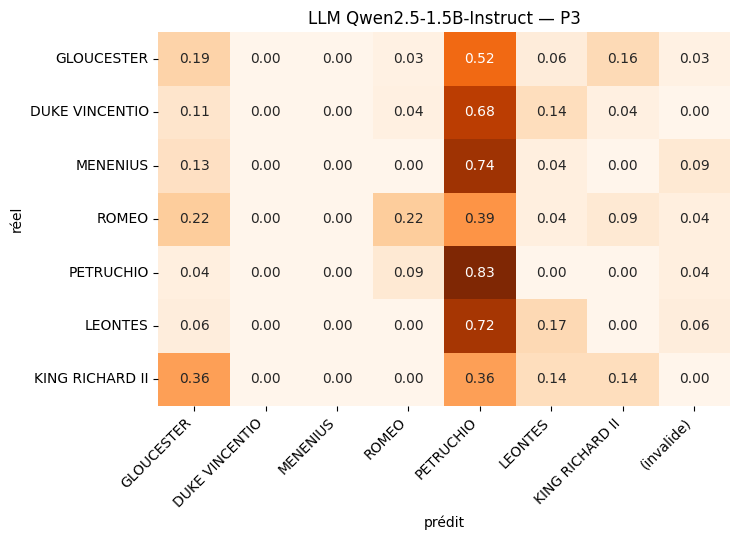

In [25]:
best = runs[best_v]
ids = to_ids(best.pred)
print(f"Meilleur prompt : {best_v}")
print(classification_report(y_eval, ids, labels=list(range(len(LABELS))), target_names=LABELS, digits=3, zero_division=0))

cm = confusion_matrix(y_eval, np.where(ids < 0, len(LABELS), ids), labels=list(range(len(LABELS) + 1)), normalize="true")[:len(LABELS)]
plt.figure(figsize=(7.5, 5.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Oranges", xticklabels=LABELS + ["(invalide)"], yticklabels=LABELS, cbar=False)
plt.title(f"LLM {MODEL_ID.split('/')[-1]} — {best_v}"); plt.xlabel("prédit"); plt.ylabel("réel"); plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

### 4.2 Biais de prédiction : le LLM répond-il toujours la même chose ?

In [26]:
dist = pd.DataFrame({"réel": eval_df.speaker.value_counts(normalize=True),
                     **{v: r.pred.fillna("(invalide)").value_counts(normalize=True) for v, r in runs.items()}}).fillna(0).round(2)
dist

,réel,P1,P2,P3,P4
(invalide),0.00,0.09,0.07,0.04,0.05
DUKE VINCENTIO,0.18,0.57,0.17,0.00,0.01
GLOUCESTER,0.19,0.00,0.01,0.15,0.86
KING RICHARD II,0.09,0.02,0.42,0.06,0.00
LEONTES,0.11,0.06,0.06,0.08,0.00
MENENIUS,0.14,0.01,0.00,0.00,0.00
PETRUCHIO,0.14,0.00,0.00,0.61,0.04
ROMEO,0.14,0.25,0.27,0.06,0.04


### 4.3 Tableau final (même test)

In [27]:
# Recalcule le meilleur modèle classique du TP 2 sur le même sous-ensemble (identique si N_TEST=None)
t0 = time.time()
ml_pred = judge.predict(vec.transform(eval_df.text.map(clean)))
ml_latency = (time.time() - t0) / len(eval_df)

final = pd.DataFrame([
    {"approche": "Classique — TF-IDF + rég. logistique", **scores(y_eval, ml_pred), "données labellisées": f"{len(train_df)} répliques", "latence / réplique (s)": ml_latency},
    *[{"approche": f"LLM {MODEL_ID.split('/')[-1]} — {v}", **scores(y_eval, to_ids(r.pred)),
       "données labellisées": "7 exemples" if v in ("P3", "P4") else "0", "latence / réplique (s)": r.latency_s.mean()} for v, r in runs.items()],
]).set_index("approche").round(4)
os.makedirs("results", exist_ok=True)
final.to_csv(f"results/tp3_final_{MODEL_ID.split('/')[-1]}.csv")
final

,accuracy,balanced_acc,precision_macro,recall_macro,f1_macro,données labellisées,latence / réplique (s)
approche,,,,,,,
Classique — TF-IDF + rég. logistique,0.5438,0.5520,0.5476,0.5520,0.5488,746 répliques,0.0001
LLM Qwen2.5-1.5B-Instruct — P1,0.2625,0.2394,0.2410,0.2094,0.1401,0,0.6868
LLM Qwen2.5-1.5B-Instruct — P2,0.2188,0.2338,0.1694,0.2045,0.1380,0,0.5488
LLM Qwen2.5-1.5B-Instruct — P3,0.2188,0.2209,0.1788,0.1933,0.1506,7 exemples,0.6478
LLM Qwen2.5-1.5B-Instruct — P4,0.2438,0.1925,0.1711,0.1685,0.1128,7 exemples,1.2957


## Conclusion

*(à relire avec vos propres chiffres : ils dépendent du modèle choisi)*

**Prompting**
- **P1 → P2** : nommer la pièce de chaque personnage aide le LLM à mobiliser ce qu'il sait du corpus (personnages cités, thèmes). C'est souvent le gain le plus important.
- **Few-shot (P3)** : améliore surtout le **respect du format** (JSON strict, noms exacts) et réduit les sorties invalides ; le gain en F1 est plus variable, et les exemples consomment des tokens d'entrée (≈ ×3 le coût).
- **Indice avant la réponse (P4)** : un petit raisonnement explicite peut aider un grand modèle mais coûte des tokens de sortie, et un petit modèle peut s'y perdre.
- Un petit modèle présente souvent un **biais de classe** (il sur-prédit les personnages les plus célèbres, ex. ROMEO) — visible dans le tableau 4.2. C'est l'équivalent LLM d'une frontière biaisée vers une classe.

**Décodage**
- Pour une tâche de **classification**, la température 0 est le bon choix : réponses reproductibles, moins de sorties invalides. Monter la température dégrade la stabilité sans améliorer le F1.
- Pour la **génération** créative, une température plus élevée diversifie les textes ; le juge TF-IDF reconnaît surtout les générations qui citent des noms ou lieux de la pièce (le style « Shakespeare générique » ne suffit pas à identifier le personnage).

**Classique vs LLM** (cf. slides 73-75)
| | Classique (TP 2) | LLM en prompting (TP 3) |
|---|---|---|
| Données | ~750 répliques labellisées | 0 à 7 exemples |
| Mise en place | entraîner, régler | écrire et tester des prompts |
| Latence / coût | ~ms par réplique, CPU | ~0,1-1 s par réplique, GPU ou API |
| Contrôle | sortie toujours valide, déterministe | parsing, sorties invalides, variabilité |
| Forces | tâche étroite, gros volume | aucune donnée nécessaire, générer du texte |

Sur cette tâche **étroite, à labels disponibles**, un modèle classique bien construit reste très compétitif face à un petit LLM, pour un coût bien inférieur. Le LLM devient intéressant quand on n'a **pas de labels**, que l'on veut **générer**, ou avec un modèle beaucoup plus grand qui connaît bien Shakespeare. Une approche **hybride** serait naturelle : le classifieur traite les cas sûrs (probabilité élevée), le LLM seulement les cas ambigus.